device: cpu | medmnist 3.0.2
train n= 4708  pneumonia share=0.74
val   n=  524  pneumonia share=0.74
test  n=  624  pneumonia share=0.62


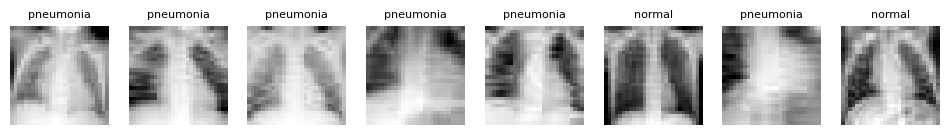

epoch  1  train loss 0.2570  val AUC 0.9829
epoch  2  train loss 0.1371  val AUC 0.9898
epoch  3  train loss 0.1152  val AUC 0.9838
epoch  4  train loss 0.1066  val AUC 0.9895
epoch  5  train loss 0.0966  val AUC 0.9939
epoch  6  train loss 0.0904  val AUC 0.9946
epoch  7  train loss 0.0872  val AUC 0.9947
epoch  8  train loss 0.0739  val AUC 0.9922
epoch  9  train loss 0.0822  val AUC 0.9959
epoch 10  train loss 0.0609  val AUC 0.9956
epoch 11  train loss 0.0626  val AUC 0.9961
epoch 12  train loss 0.0583  val AUC 0.9956
epoch 13  train loss 0.0500  val AUC 0.9962
epoch 14  train loss 0.0477  val AUC 0.9965
epoch 15  train loss 0.0460  val AUC 0.9965
best val AUC: 0.9965
fitted temperature T = 1.094  (model was overconfident)


,Accuracy,AUC,ECE,NLL,Brier
Uncalibrated,0.8574,0.9741,0.1048,0.5392,0.1178
Temperature scaled,0.8574,0.9741,0.1010,0.5023,0.1162


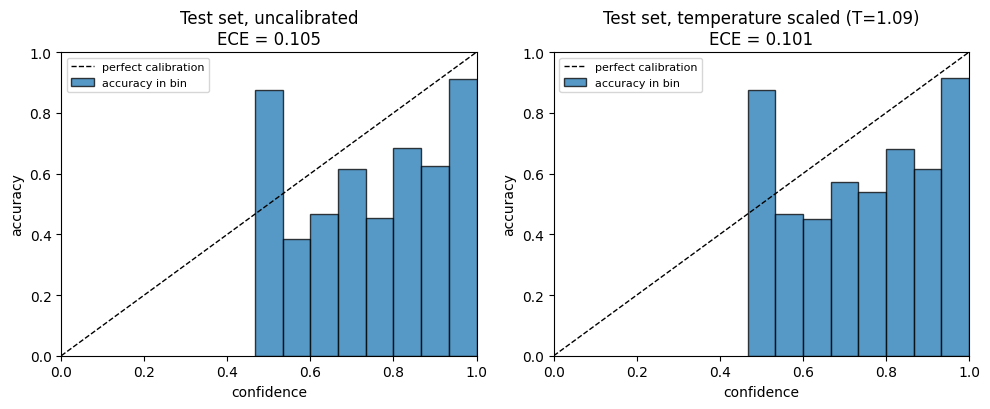

Accuracy                             ECE  \
Model                   Temperature scaled Uncalibrated Temperature scaled   
Shift          Severity                                                      
Blur           0                     0.857        0.857              0.101   
               1                     0.808        0.808              0.147   
               2                     0.692        0.692              0.277   
               3                     0.625        0.625              0.370   
               4                     0.625        0.625              0.375   
Contrast loss  0                     0.857        0.857              0.101   
               1                     0.780        0.780              0.175   
               2                     0.697        0.697              0.279   
               3                     0.625        0.625              0.375   
               4                     0.625        0.625              0.375   
Gaussian noise 0                     0.857        0.857              0.101   
               1                     0.790        0.790              0.068   
               2                     0.686        0.686              0.112   
               3                     0.662        0.662              0.143   
               4                     0.684        0.684              0.032   

                                      
Model                   Uncalibrated  
Shift          Severity               
Blur           0               0.105  
               1               0.150  
               2               0.278  
               3               0.370  
               4               0.375  
Contrast loss  0               0.105  
               1               0.178  
               2               0.282  
               3               0.375  
               4               0.375  
Gaussian noise 0               0.105  
               1               0.073  
               2               0.126  
               3               0.160  
               4               0.034

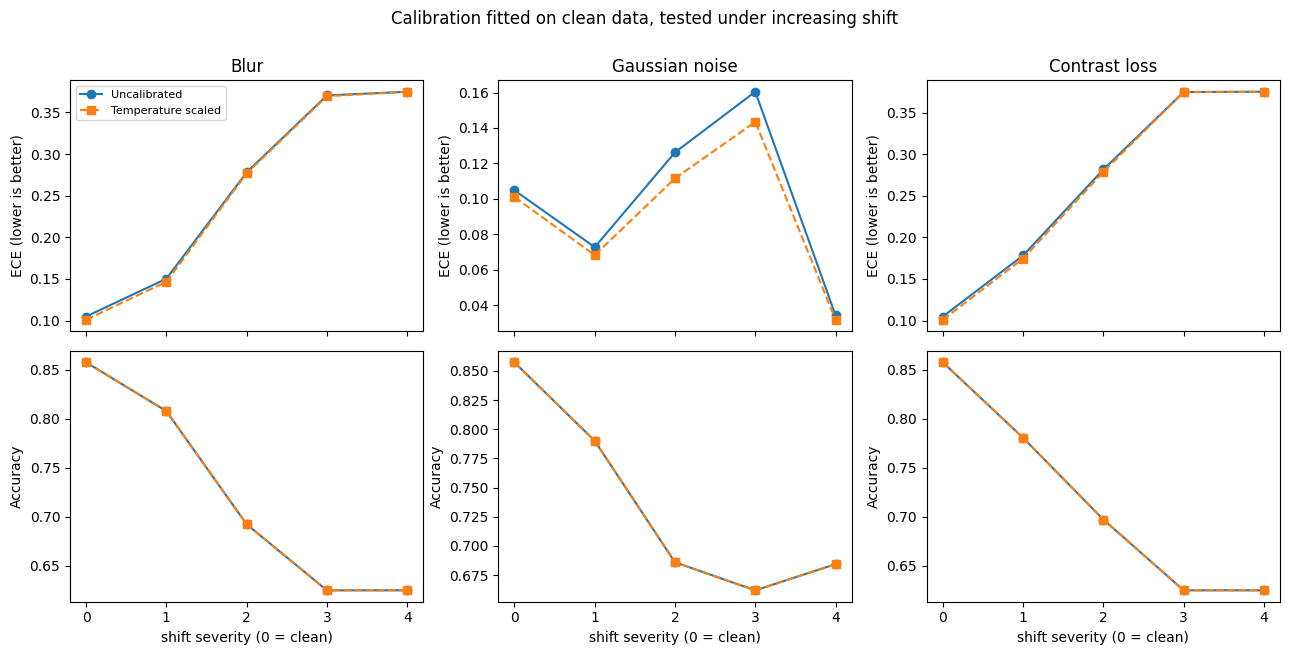

wrong predictions on test: 89 / 624;  wrong with confidence > 0.9: 50


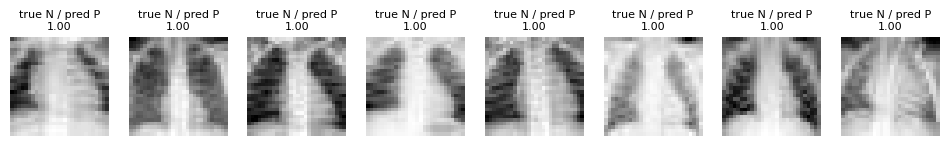


Clean test set: accuracy 85.7%, AUC 0.974.
Temperature scaling (T = 1.09) changed ECE from 0.105 to 0.101 and NLL from 0.539 to 0.502, with accuracy unchanged.
Under the strongest shift (contrast loss, level 0.8), accuracy was 62.5% and ECE was 0.375 after temperature scaling
(clean calibrated ECE: 0.101; 3.7x higher).



In [2]:
!pip -q install medmnist

import random, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score
import medmnist
from medmnist import PneumoniaMNIST

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| medmnist", medmnist.__version__)

# ---------- 1. DATA ----------
def load(split):
    ds = PneumoniaMNIST(split=split, download=True, size=28)
    x = torch.tensor(ds.imgs, dtype=torch.float32).unsqueeze(1) / 255.0
    y = torch.tensor(ds.labels, dtype=torch.long).view(-1)
    return x, y

x_tr, y_tr = load("train"); x_va, y_va = load("val"); x_te, y_te = load("test")
MEAN, STD = x_tr.mean().item(), x_tr.std().item()
norm = lambda x: (x - MEAN) / STD
for name, y in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(f"{name:5s} n={len(y):5d}  pneumonia share={y.float().mean():.2f}")

fig, ax = plt.subplots(1, 8, figsize=(12, 1.8))
for i in range(8):
    ax[i].imshow(x_tr[i, 0], cmap="gray"); ax[i].set_title(["normal", "pneumonia"][y_tr[i]], fontsize=8); ax[i].axis("off")
plt.show()

# ---------- 2. MODEL + TRAINING ----------
class SmallCNN(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 3 * 3, 128), nn.ReLU(), nn.Linear(128, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def augment(x):
    flip = torch.rand(x.size(0), device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(-1), x)
    shift = torch.randint(-2, 3, (2,)).tolist()
    return torch.roll(x, shifts=shift, dims=(-2, -1))

@torch.no_grad()
def get_logits(model, x, bs=512):
    model.eval()
    return torch.cat([model(norm(x[i:i + bs]).to(DEVICE)).cpu() for i in range(0, len(x), bs)])

model = SmallCNN().to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
EPOCHS = 15
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
train_dl = DataLoader(TensorDataset(x_tr, y_tr), batch_size=128, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))

best_auc, best_state = -1, None
for ep in range(1, EPOCHS + 1):
    model.train(); total = 0
    for xb, yb in train_dl:
        xb, yb = augment(norm(xb).to(DEVICE)), yb.to(DEVICE)
        loss = F.cross_entropy(model(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step(); total += loss.item() * len(yb)
    sched.step()
    p_va = get_logits(model, x_va).softmax(1)[:, 1].numpy()
    auc = roc_auc_score(y_va.numpy(), p_va)
    if auc > best_auc:
        best_auc, best_state = auc, {k: v.detach().clone() for k, v in model.state_dict().items()}
    print(f"epoch {ep:2d}  train loss {total / len(y_tr):.4f}  val AUC {auc:.4f}")
model.load_state_dict(best_state)
print(f"best val AUC: {best_auc:.4f}")

# ---------- 3. CALIBRATION METRICS ----------
def ece_score(probs, labels, n_bins=15):
    conf, pred = probs.max(1); correct = pred.eq(labels).float()
    edges = torch.linspace(0, 1, n_bins + 1); ece = torch.zeros(1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.float().mean() * (conf[m].mean() - correct[m].mean()).abs()
    return ece.item()

def evaluate(logits, labels, T=1.0):
    probs = (logits / T).softmax(1)
    return {"Accuracy": probs.argmax(1).eq(labels).float().mean().item(),
            "AUC": roc_auc_score(labels.numpy(), probs[:, 1].numpy()),
            "ECE": ece_score(probs, labels),
            "NLL": F.cross_entropy(logits / T, labels).item(),
            "Brier": ((probs[:, 1] - labels.float()) ** 2).mean().item()}

def reliability(ax, logits, labels, T, title, n_bins=15):
    probs = (logits / T).softmax(1); conf, pred = probs.max(1); correct = pred.eq(labels).float()
    edges = torch.linspace(0, 1, n_bins + 1); mids, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            mids.append(((lo + hi) / 2).item()); accs.append(correct[m].mean().item())
    ax.bar(mids, accs, width=1 / n_bins, edgecolor="black", alpha=0.75, label="accuracy in bin")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
    ax.set_title(f"{title}\nECE = {ece_score(probs, labels):.3f}"); ax.legend(fontsize=8, loc="upper left")

# ---------- 4. TEMPERATURE SCALING ----------
logits_va, logits_te = get_logits(model, x_va), get_logits(model, x_te)
log_T = torch.zeros(1, requires_grad=True)
opt_T = torch.optim.LBFGS([log_T], lr=0.1, max_iter=200)
def closure():
    opt_T.zero_grad(); loss = F.cross_entropy(logits_va / log_T.exp(), y_va); loss.backward(); return loss
opt_T.step(closure)
T = log_T.exp().item()
print(f"fitted temperature T = {T:.3f}  ({'model was overconfident' if T > 1 else 'model was underconfident'})")

res = pd.DataFrame({"Uncalibrated": evaluate(logits_te, y_te), "Temperature scaled": evaluate(logits_te, y_te, T)}).T
display(res.round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
reliability(ax[0], logits_te, y_te, 1.0, "Test set, uncalibrated")
reliability(ax[1], logits_te, y_te, T, f"Test set, temperature scaled (T={T:.2f})")
plt.tight_layout(); plt.savefig("reliability_diagrams.png", dpi=200); plt.show()

# ---------- 5. DISTRIBUTION SHIFT ----------
def gaussian_blur(x, sigma):
    if sigma == 0: return x
    k = int(2 * round(3 * sigma) + 1); r = torch.arange(k) - k // 2
    g = torch.exp(-r.float() ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), g.view(1, 1, 1, k))
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), g.view(1, 1, k, 1))

gen = torch.Generator().manual_seed(SEED)
SHIFTS = {
    "Blur":           (lambda x, s: gaussian_blur(x, s), [0, 0.5, 1.0, 1.5, 2.0]),
    "Gaussian noise": (lambda x, s: (x + s * torch.randn(x.shape, generator=gen)).clamp(0, 1), [0, 0.05, 0.10, 0.15, 0.20]),
    "Contrast loss":  (lambda x, s: (x.mean((2, 3), keepdim=True) + (1 - s) * (x - x.mean((2, 3), keepdim=True))).clamp(0, 1),
                       [0, 0.2, 0.4, 0.6, 0.8]),
}
rows = []
for name, (fn, levels) in SHIFTS.items():
    for sev, lvl in enumerate(levels):
        lg = get_logits(model, fn(x_te.clone(), lvl))
        for label, t in [("Uncalibrated", 1.0), ("Temperature scaled", T)]:
            rows.append({"Shift": name, "Severity": sev, "Level": lvl, "Model": label, **evaluate(lg, y_te, t)})
shift_df = pd.DataFrame(rows)
display(shift_df.pivot_table(index=["Shift", "Severity"], columns="Model", values=["Accuracy", "ECE"]).round(3))

fig, ax = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for j, name in enumerate(SHIFTS):
    d = shift_df[shift_df.Shift == name]
    for label, style in [("Uncalibrated", "o-"), ("Temperature scaled", "s--")]:
        dd = d[d.Model == label]
        ax[0, j].plot(dd.Severity, dd.ECE, style, label=label)
        ax[1, j].plot(dd.Severity, dd.Accuracy, style, label=label)
    ax[0, j].set_title(name); ax[0, j].set_ylabel("ECE (lower is better)"); ax[1, j].set_ylabel("Accuracy")
    ax[1, j].set_xlabel("shift severity (0 = clean)")
ax[0, 0].legend(fontsize=8)
plt.suptitle("Calibration fitted on clean data, tested under increasing shift", y=1.0)
plt.tight_layout(); plt.savefig("calibration_under_shift.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- 6. CONFIDENTLY WRONG CASES ----------
probs_te = (logits_te / T).softmax(1); conf, pred = probs_te.max(1)
wrong = (pred != y_te).nonzero().view(-1)
top = wrong[conf[wrong].argsort(descending=True)][:8]
print(f"wrong predictions on test: {len(wrong)} / {len(y_te)};  wrong with confidence > 0.9: {(conf[wrong] > 0.9).sum().item()}")
if len(top):
    fig, ax = plt.subplots(1, len(top), figsize=(12, 2), squeeze=False)
    for i, idx in enumerate(top):
        ax[0, i].imshow(x_te[idx, 0], cmap="gray"); ax[0, i].axis("off")
        ax[0, i].set_title(f"true {['N','P'][y_te[idx]]} / pred {['N','P'][pred[idx]]}\n{conf[idx]:.2f}", fontsize=8)
    plt.show()

# ---------- 7. SUMMARY ----------
u, s = res.loc["Uncalibrated"], res.loc["Temperature scaled"]
worst = shift_df[(shift_df.Severity == 4) & (shift_df.Model == "Temperature scaled")].sort_values("ECE").iloc[-1]
clean_ece = s["ECE"]
ratio = f"; {worst['ECE'] / clean_ece:.1f}x higher" if clean_ece > 0.005 else ""
summary = f"""
Clean test set: accuracy {u['Accuracy']:.1%}, AUC {u['AUC']:.3f}.
Temperature scaling (T = {T:.2f}) changed ECE from {u['ECE']:.3f} to {s['ECE']:.3f} and NLL from {u['NLL']:.3f} to {s['NLL']:.3f}, with accuracy unchanged.
Under the strongest shift ({worst['Shift'].lower()}, level {worst['Level']}), accuracy was {worst['Accuracy']:.1%} and ECE was {worst['ECE']:.3f} after temperature scaling
(clean calibrated ECE: {clean_ece:.3f}{ratio}).
"""
print(summary)
open("results_summary.txt", "w").write(summary)
res.round(4).to_csv("results_clean.csv"); shift_df.round(4).to_csv("results_shift.csv", index=False)